# PART A — The 10-step Machine Learning Cycle

## Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle, os, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score
from prettytable import PrettyTable

os.makedirs("figures", exist_ok=True)
print("Libraries imported.")

ModuleNotFoundError: No module named 'prettytable'

## Step 2: Load Sample Data
Looks for `sample-data.csv` in the current folder, `/content` (Colab), or `D:\5th sem\AI`. If not found in Colab it opens the upload dialog.

In [2]:
candidates = ["sample-data.csv", "/content/sample-data.csv", r"D:\5th sem\AI\sample-data.csv"]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    try:
        from google.colab import files      # only works inside Colab
        print("Please upload sample-data.csv")
        files.upload()
        path = "sample-data.csv"
    except ImportError:
        raise FileNotFoundError("sample-data.csv not found. Put it next to this notebook.")

sample_data = pd.read_csv(path)
print("Loaded from:", path)
print("\nSample Data:\n============\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data)

Loaded from: sample-data.csv

Sample Data:

    PClass  Gender Sibling     Embarked Survived
0    Third    Male     One  Southampton       No
1   Second  Female    Zero  Southampton      Yes
2    Third    Male    Zero  Southampton       No
3    Third  Female   Three  Southampton      Yes
4    Third    Male    Zero   Queenstown       No
5    First  Female   Three  Southampton      Yes
6    Third    Male    Zero  Southampton       No
7    Third    Male    Zero  Southampton      Yes
8    First    Male    Zero  Southampton       No
9   Second    Male    Zero  Southampton      Yes
10   Third    Male     One   Queenstown       No
11   First    Male    Zero    Cherbourg      Yes
12   First    Male    Zero    Cherbourg       No
13  Second  Female    Zero  Southampton      Yes
14  Second    Male    Zero  Southampton       No
15   Third    Male     One    Cherbourg      Yes
16   Third    Male     Two    Cherbourg       No
17   Third    Male    Zero  Southampton      Yes
18   Third    Male    Zer

## Step 3: Understand and Pre-process Sample Data

In [3]:
print("Attributes:", list(sample_data.columns))
print("Number of Instances:", sample_data["PClass"].count())
print("\nMissing values per column:\n", sample_data.isnull().sum())
print("\nClass balance (Survived):\n", sample_data["Survived"].value_counts())
baseline = sample_data["Survived"].value_counts(normalize=True).max()
print(f"\nMajority-class BASELINE accuracy = {baseline:.2f}")
for c in ["PClass", "Gender", "Sibling", "Embarked"]:
    print(f"\nSurvival rate by {c}:")
    print(sample_data.groupby(c)["Survived"].apply(lambda s: (s == "Yes").mean()).round(2))

Attributes: ['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']
Number of Instances: 100

Missing values per column:
 PClass      0
Gender      0
Sibling     0
Embarked    0
Survived    0
dtype: int64

Class balance (Survived):
 Survived
No     50
Yes    50
Name: count, dtype: int64

Majority-class BASELINE accuracy = 0.50

Survival rate by PClass:
PClass
First     0.65
Second    0.60
Third     0.42
Name: Survived, dtype: float64

Survival rate by Gender:
Gender
Female    0.79
Male      0.29
Name: Survived, dtype: float64

Survival rate by Sibling:
Sibling
One      0.55
Three    0.33
Two      0.33
Zero     0.51
Name: Survived, dtype: float64

Survival rate by Embarked:
Embarked
Cherbourg      0.44
Queenstown     0.56
Southampton    0.51
Name: Survived, dtype: float64


**Step 3.2 / Step 4:** the data is already clean (no nulls) and the features are already extracted, so no preprocessing / feature extraction is required.

**Baseline note:** this sample is perfectly balanced (50 Yes / 50 No), so the "always No" baseline is **50 %**, not the ~62 % of the full Titanic data.

## Step 5: Label Encoding (input and output → numeric)
### Step 5.1: Train the Label Encoders

In [4]:
pclass_label_encoder   = LabelEncoder().fit(["First", "Second", "Third"])
gender_label_encoder   = LabelEncoder().fit(["Male", "Female"])
sibling_label_encoder  = LabelEncoder().fit(["Zero", "One", "Two", "Three"])
embarked_label_encoder = LabelEncoder().fit(["Southampton", "Cherbourg", "Queenstown"])
survived_label_encoder = LabelEncoder().fit(["Yes", "No"])

for name, enc in [("pclass", pclass_label_encoder), ("gender", gender_label_encoder),
                  ("sibling", sibling_label_encoder), ("embarked", embarked_label_encoder),
                  ("survived", survived_label_encoder)]:
    with open(f"{name}_encoder.pkl", "wb") as f:
        pickle.dump(enc, f)
    print(f"{name:9s} classes_ ->", list(enc.classes_))

pclass    classes_ -> [np.str_('First'), np.str_('Second'), np.str_('Third')]
gender    classes_ -> [np.str_('Female'), np.str_('Male')]
sibling   classes_ -> [np.str_('One'), np.str_('Three'), np.str_('Two'), np.str_('Zero')]
embarked  classes_ -> [np.str_('Cherbourg'), np.str_('Queenstown'), np.str_('Southampton')]
survived  classes_ -> [np.str_('No'), np.str_('Yes')]


### Step 5.2: Label Encode the Output

In [5]:
original_sample_data = sample_data.copy()
sample_data_encoded_output = sample_data.copy()
sample_data_encoded_output["Survived"] = survived_label_encoder.transform(sample_data["Survived"])
print(sample_data_encoded_output.head(10))
sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False)

   PClass  Gender Sibling     Embarked  Survived
0   Third    Male     One  Southampton         0
1  Second  Female    Zero  Southampton         1
2   Third    Male    Zero  Southampton         0
3   Third  Female   Three  Southampton         1
4   Third    Male    Zero   Queenstown         0
5   First  Female   Three  Southampton         1
6   Third    Male    Zero  Southampton         0
7   Third    Male    Zero  Southampton         1
8   First    Male    Zero  Southampton         0
9  Second    Male    Zero  Southampton         1


### Step 5.3: Label Encode the Input

In [6]:
sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded["PClass"]   = pclass_label_encoder.transform(sample_data_encoded["PClass"])
sample_data_encoded["Gender"]   = gender_label_encoder.transform(sample_data_encoded["Gender"])
sample_data_encoded["Sibling"]  = sibling_label_encoder.transform(sample_data_encoded["Sibling"])
sample_data_encoded["Embarked"] = embarked_label_encoder.transform(sample_data_encoded["Embarked"])
print("Original:\n", original_sample_data.head(8))
print("\nEncoded:\n", sample_data_encoded.head(8))
sample_data_encoded.to_csv("sample-data-encoded.csv", index=False)

Original:
    PClass  Gender Sibling     Embarked Survived
0   Third    Male     One  Southampton       No
1  Second  Female    Zero  Southampton      Yes
2   Third    Male    Zero  Southampton       No
3   Third  Female   Three  Southampton      Yes
4   Third    Male    Zero   Queenstown       No
5   First  Female   Three  Southampton      Yes
6   Third    Male    Zero  Southampton       No
7   Third    Male    Zero  Southampton      Yes

Encoded:
    PClass  Gender  Sibling  Embarked  Survived
0       2       1        0         2         0
1       1       0        3         2         1
2       2       1        3         2         0
3       2       0        1         2         1
4       2       1        3         1         0
5       0       0        1         2         1
6       2       1        3         2         0
7       2       1        3         2         1


# Step 6: Execute the Training Phase
## Step 6.1: Split Sample Data into Training (80 %) and Testing (20 %)

In [7]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded, test_size=0.2, random_state=42, shuffle=False)
print("Train rows:", len(training_data_encoded), "| Test rows:", len(testing_data_encoded))

Train rows: 80 | Test rows: 20


## Step 6.2: Split Input Vectors and Labels

In [8]:
input_vector_train = training_data_encoded.drop(columns=["Survived"])
output_label_train = training_data_encoded["Survived"]
print(input_vector_train.head()); print(output_label_train.head())

   PClass  Gender  Sibling  Embarked
0       2       1        0         2
1       1       0        3         2
2       2       1        3         2
3       2       0        1         2
4       2       1        3         1
0    0
1    1
2    0
3    1
4    0
Name: Survived, dtype: int64


## Step 6.3: Train the Support Vector Classifier

In [9]:
svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)

SVC(gamma='auto', random_state=0)


## Step 6.4: Save the Trained Model

In [10]:
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved svc_trained_model.pkl")

Saved svc_trained_model.pkl


# Step 7: Execute the Testing Phase
## 7.1 Split test inputs / labels, 7.2 Load model, 7.3 Predict

In [11]:
input_vector_test = testing_data_encoded.drop(columns=["Survived"])
output_label_test = testing_data_encoded["Survived"]

model = pickle.load(open("svc_trained_model.pkl", "rb"))
preds = model.predict(input_vector_test)

model_predictions = testing_data_encoded.copy()
model_predictions["Predictions"] = preds
model_predictions.to_csv("model-predictions.csv", index=False)
print(model_predictions)

    PClass  Gender  Sibling  Embarked  Survived  Predictions
80       2       1        2         2         0            0
81       2       0        3         2         1            1
82       2       1        3         2         0            0
83       0       1        0         2         1            0
84       1       1        3         2         0            0
85       2       0        0         1         1            1
86       1       1        3         2         0            0
87       0       0        0         2         1            1
88       2       1        3         2         0            0
89       1       0        3         2         1            1
90       1       1        3         2         0            0
91       1       0        3         2         1            1
92       2       1        3         0         0            0
93       0       1        0         2         1            0
94       0       1        0         2         0            0
95       2       1      

## Step 7.4: Accuracy Score

In [12]:
model_accuracy_score = accuracy_score(model_predictions["Survived"], model_predictions["Predictions"])
print("Accuracy Score:", round(model_accuracy_score, 2))

Accuracy Score: 0.8


# Step 8: Execute the Application Phase
## 8.1 Take input from user
The original used `input()`. To make the notebook run top-to-bottom in Colab without stopping, a default example is used; set `USE_KEYBOARD = True` to type values interactively.

In [13]:
USE_KEYBOARD = False
if USE_KEYBOARD:
    pclass_input   = input("PClass (First,Second,Third): ").strip()
    gender_input   = input("Gender (Male,Female): ").strip()
    sibling_input  = input("Sibling (Zero,One,Two,Three): ").strip()
    embarked_input = input("Embarked (Cherbourg,Southampton,Queenstown): ").strip()
else:
    pclass_input, gender_input, sibling_input, embarked_input = "First", "Male", "Three", "Queenstown"
print(pclass_input, gender_input, sibling_input, embarked_input)

First Male Three Queenstown


## 8.2 Convert user input into a feature vector

In [14]:
user_input = pd.DataFrame({"PClass": [pclass_input], "Gender": [gender_input],
                           "Sibling": [sibling_input], "Embarked": [embarked_input]})
print(user_input)

  PClass Gender Sibling    Embarked
0  First   Male   Three  Queenstown


## 8.3 Label-encode the feature vector (using the *saved* encoders)

In [15]:
ENCODERS = {}
for col, name in [("PClass", "pclass"), ("Gender", "gender"), ("Sibling", "sibling"), ("Embarked", "embarked")]:
    with open(f"{name}_encoder.pkl", "rb") as f:
        ENCODERS[col] = pickle.load(f)

expected_features = ["PClass", "Gender", "Sibling", "Embarked"]
user_input = user_input[expected_features]
for col, enc in ENCODERS.items():
    unknown = set(user_input[col].astype(str)) - set(enc.classes_)
    if unknown:
        raise ValueError(f"Unknown categories for {col}: {sorted(unknown)}")

unseen_data_features = user_input.copy()
for col, enc in ENCODERS.items():
    unseen_data_features[col] = enc.transform(unseen_data_features[col].astype(str))
print(unseen_data_features)

   PClass  Gender  Sibling  Embarked
0       0       1        1         1


## 8.4 Load model, 8.5 Predict

In [16]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
predicted_survival = model.predict(unseen_data_features)
prediction = "SURVIVED" if predicted_survival[0] == 1 else "NOT SURVIVED"
t = PrettyTable(); t.add_column("       ** Prediction **       ", [prediction]); print(t)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|          NOT SURVIVED          |
+--------------------------------+


# Step 9: Feedback Phase
1. After some time collect feedback from domain experts and users of the deployed system.
2. List possible improvements (more passengers, Age/Fare features, other models, tuning, probability output).

# Step 10: Improve the Model
This is done in Parts B–D below: more models, tuning, cross-validation and leakage-safe pipelines.

# PART B — Model comparison, evaluation, tuning and persistence

## B.1 Setup: stratified split
Because the data is tiny (100 rows), a **stratified** 80/20 split is used here (the original Step 6.1 used an ordered split). Encoders from Part A are fitted on the category lists only (not on statistics of the data), so no information leaks.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)
import matplotlib.pyplot as plt
import joblib

FEATURES = ["PClass", "Gender", "Sibling", "Embarked"]
X = original_sample_data[FEATURES]
y = (original_sample_data["Survived"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class balance:", y_train.value_counts().to_dict())

def make_pipe(clf, feats=FEATURES):
    pre = ColumnTransformer([("ohe", OneHotEncoder(handle_unknown="ignore"), feats)])
    return Pipeline([("pre", pre), ("clf", clf)])

Train: (80, 4)  Test: (20, 4)
Train class balance: {0: 40, 1: 40}


## B.2 Train and compare Logistic Regression, Decision Tree, Random Forest (one protocol)

In [18]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42),
}
rows, fitted = [], {}
for name, clf in models.items():
    pipe = make_pipe(clf).fit(X_train, y_train)
    fitted[name] = pipe
    p = pipe.predict(X_test)
    auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    rows.append({"Model": name, "Train acc": round(pipe.score(X_train, y_train), 3),
                 "Test acc": round(accuracy_score(y_test, p), 3), "AUC": round(auc, 3)})
comparison = pd.DataFrame(rows).set_index("Model")
print(f"Baseline (majority class) accuracy: {max(y_test.mean(), 1 - y_test.mean()):.2f}\n")
comparison

Baseline (majority class) accuracy: 0.50



,Train acc,Test acc,AUC
Model,,,
Logistic Regression,0.787,0.50,0.565
Decision Tree,0.825,0.55,0.560
Random Forest,0.825,0.50,0.555


## B.3 Confusion matrix and classification report

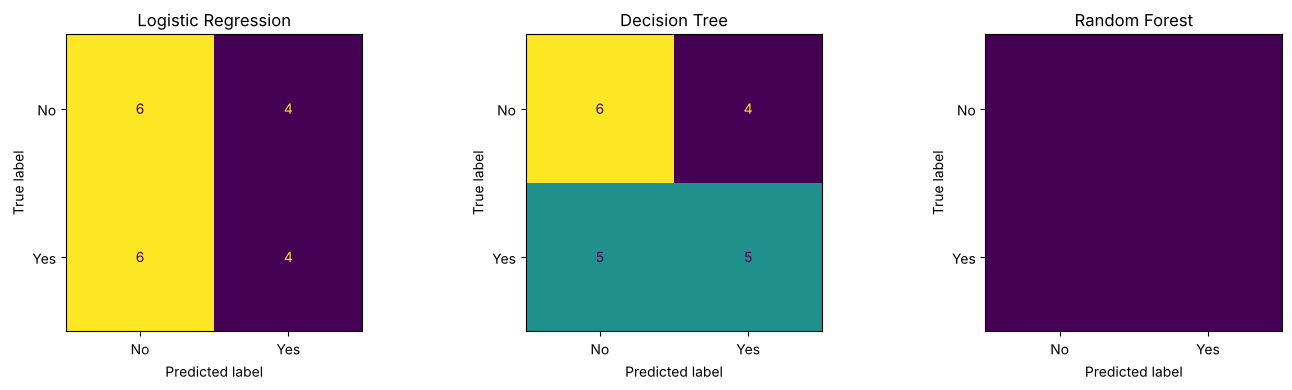

 Logistic Regression 
              precision    recall  f1-score   support

Not survived       0.50      0.60      0.55        10
    Survived       0.50      0.40      0.44        10

    accuracy                           0.50        20
   macro avg       0.50      0.50      0.49        20
weighted avg       0.50      0.50      0.49        20

 Decision Tree 
              precision    recall  f1-score   support

Not survived       0.55      0.60      0.57        10
    Survived       0.56      0.50      0.53        10

    accuracy                           0.55        20
   macro avg       0.55      0.55      0.55        20
weighted avg       0.55      0.55      0.55        20

 Random Forest 
              precision    recall  f1-score   support

Not survived       0.50      0.50      0.50        10
    Survived       0.50      0.50      0.50        10

    accuracy                           0.50        20
   macro avg       0.50      0.50      0.50        20
weighted avg       0

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)),
                           display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png", dpi=120); plt.show()
for name, pipe in fitted.items():
    print("=" * 55, "\n", name, "\n", "=" * 55)
    print(classification_report(y_test, pipe.predict(X_test), target_names=["Not survived", "Survived"]))

## B.4 ROC curve and AUC (Exercise 2)

Best model by AUC: Logistic Regression


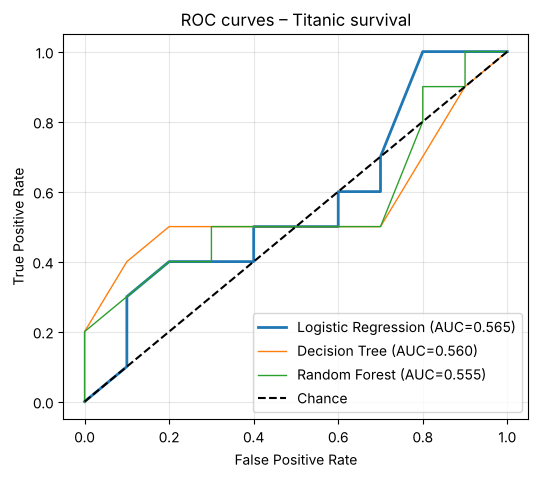

In [20]:
best_name = comparison["AUC"].idxmax()
print("Best model by AUC:", best_name)
plt.figure(figsize=(6, 5))
for name, pipe in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, lw=2 if name == best_name else 1,
             label=f"{name} (AUC={roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves – Titanic survival"); plt.legend(loc="lower right"); plt.grid(alpha=.3)
plt.savefig("figures/roc_curve.png", dpi=150, bbox_inches="tight"); plt.show()

## B.5 Hyper-parameter tuning with `GridSearchCV`

In [21]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "Decision Tree":       (DecisionTreeClassifier(random_state=42),
                            {"clf__max_depth": [2, 3, 4, 5, None], "clf__min_samples_leaf": [1, 2, 5]}),
    "Random Forest":       (RandomForestClassifier(random_state=42),
                            {"clf__n_estimators": [50, 100, 200], "clf__max_depth": [3, 5, None],
                             "clf__min_samples_leaf": [1, 2, 4]}),
}
tuned, tune_rows = {}, []
for name, (clf, grid) in param_grids.items():
    gs = GridSearchCV(make_pipe(clf), grid, cv=cv5, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs
    tune_rows.append({"Model": name, "Best CV acc": round(gs.best_score_, 3),
                      "Test acc": round(gs.score(X_test, y_test), 3), "Best params": gs.best_params_})
tuning = pd.DataFrame(tune_rows).set_index("Model")
pd.set_option("display.max_colwidth", 120)
tuning

,Best CV acc,Test acc,Best params
Model,,,
Logistic Regression,0.750,0.65,{'clf__C': 0.01}
Decision Tree,0.738,0.65,"{'clf__max_depth': 2, 'clf__min_samples_leaf': 5}"
Random Forest,0.725,0.65,"{'clf__max_depth': 3, 'clf__min_samples_leaf': 4, 'clf__n_estimators': 50}"


## B.6 Persist the winning estimator with `joblib`

In [22]:
winner = tuning["Best CV acc"].idxmax()
best_estimator = tuned[winner].best_estimator_
joblib.dump(best_estimator, "titanic_best_model.joblib")
print("Winner:", winner, "->", tuned[winner].best_params_)

reloaded = joblib.load("titanic_best_model.joblib")
demo = pd.DataFrame([{"PClass": "First", "Gender": "Female", "Sibling": "One", "Embarked": "Cherbourg"}])
print("Reloaded model prediction for a 1st-class female:",
      "SURVIVED" if reloaded.predict(demo)[0] == 1 else "NOT SURVIVED",
      "| P(survive) =", round(reloaded.predict_proba(demo)[0, 1], 3))

Winner: Logistic Regression -> {'clf__C': 0.01}
Reloaded model prediction for a 1st-class female: SURVIVED | P(survive) = 0.539


# PART C — In-Lab Exercises

## Exercise 1 — With vs without the family feature
The dataset has no `FamilySize`; `IsAlone` is derived from `Sibling` (`Zero` ⇒ alone). Three variants are compared: **full** (PClass, Gender, Sibling, Embarked), **+IsAlone**, and **without any family feature**. Mean accuracy over repeated 5-fold CV.

In [23]:
from sklearn.model_selection import RepeatedStratifiedKFold
X_ex = X.copy()
X_ex["IsAlone"] = (X_ex["Sibling"] == "Zero").astype(int).astype(str)

variants = {
    "Without Sibling/IsAlone": ["PClass", "Gender", "Embarked"],
    "With Sibling (original)": ["PClass", "Gender", "Sibling", "Embarked"],
    "With IsAlone instead of Sibling": ["PClass", "Gender", "IsAlone", "Embarked"],
    "With Sibling + IsAlone": ["PClass", "Gender", "Sibling", "IsAlone", "Embarked"],
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
base_models = {"Logistic Regression": LogisticRegression(max_iter=1000),
               "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
               "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42)}
res = {}
for vname, feats in variants.items():
    res[vname] = {m: cross_val_score(make_pipe(c, feats), X_ex[feats], y, cv=rcv).mean()
                  for m, c in base_models.items()}
ex1 = pd.DataFrame(res).T.round(3)
ex1["(delta) Sibling vs none – LR"] = (ex1.loc["With Sibling (original)", "Logistic Regression"]
                                       - ex1.loc["Without Sibling/IsAlone", "Logistic Regression"]).round(3)
delta = (ex1.loc["With Sibling (original)", list(base_models)] -
         ex1.loc["Without Sibling/IsAlone", list(base_models)]).round(3)
display(ex1.drop(columns="(delta) Sibling vs none – LR"))
print("Accuracy delta (with Sibling minus without):\n", delta.to_string())

,Logistic Regression,Decision Tree,Random Forest
Without Sibling/IsAlone,0.726,0.699,0.699
With Sibling (original),0.714,0.678,0.678
With IsAlone instead of Sibling,0.720,0.687,0.685
With Sibling + IsAlone,0.714,0.675,0.676


Accuracy delta (with Sibling minus without):
 Logistic Regression   -0.012
Decision Tree         -0.021
Random Forest         -0.021


## Exercise 3 — 5-fold cross-validation stability

In [24]:
ex3 = []
for name, clf in base_models.items():
    s = cross_val_score(make_pipe(clf), X, y, cv=cv5, scoring="accuracy")
    ex3.append({"Model": name, "Mean acc": round(s.mean(), 3), "Std": round(s.std(), 3),
                "Folds": np.round(s, 2).tolist()})
ex3 = pd.DataFrame(ex3).set_index("Model"); ex3

,Mean acc,Std,Folds
Model,,,
Logistic Regression,0.71,0.097,"[0.75, 0.8, 0.8, 0.55, 0.65]"
Decision Tree,0.68,0.117,"[0.7, 0.8, 0.8, 0.5, 0.6]"
Random Forest,0.67,0.108,"[0.75, 0.7, 0.8, 0.5, 0.6]"


## Exercise 4 — Add `KNeighborsClassifier` and `SVC`, re-run the comparison **unchanged**

In [25]:
models_ex4 = dict(models)
models_ex4["KNN"] = KNeighborsClassifier(n_neighbors=5)
models_ex4["SVC"] = SVC(probability=True, random_state=42)

rows4 = []
for name, clf in models_ex4.items():          # identical loop to B.2
    pipe = make_pipe(clf).fit(X_train, y_train)
    p = pipe.predict(X_test)
    rows4.append({"Model": name, "Train acc": round(pipe.score(X_train, y_train), 3),
                  "Test acc": round(accuracy_score(y_test, p), 3),
                  "AUC": round(roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]), 3),
                  "CV acc (5-fold)": round(cross_val_score(make_pipe(clf), X, y, cv=cv5).mean(), 3)})
comparison5 = pd.DataFrame(rows4).set_index("Model"); comparison5

,Train acc,Test acc,AUC,CV acc (5-fold)
Model,,,,
Logistic Regression,0.787,0.50,0.565,0.71
Decision Tree,0.825,0.55,0.560,0.68
Random Forest,0.825,0.50,0.555,0.67
KNN,0.787,0.60,0.595,0.68
SVC,0.775,0.60,0.605,0.72


## Exercise 5 — Summary report and deployment recommendation
(Also saved to `report.md`.)

In [26]:
cv_best = comparison5["CV acc (5-fold)"].idxmax()
report = f"""# Lab 05 Report – Titanic Survival Classification

## EDA findings
* 100 passengers, 4 categorical features (PClass, Gender, Sibling, Embarked), **no missing values**.
* Classes are perfectly balanced (50 survived / 50 not) so the majority baseline is **50 %**.
* Women survived far more often than men; first/second class more than third class (see survival-rate tables in Step 3).

## Three-model comparison (stratified 80/20 split)
{comparison.to_markdown()}

## Hyper-parameter tuning (GridSearchCV, 5-fold)
{tuning.drop(columns="Best params").to_markdown()}

Best parameters:
""" + "\n".join(f"* {k}: `{v.best_params_}`" for k, v in tuned.items()) + f"""

## Five-model comparison (Exercise 4) incl. 5-fold CV accuracy
{comparison5.to_markdown()}

## Cross-validation stability (Exercise 3)
{ex3.drop(columns="Folds").to_markdown()}

## Recommendation
Tuned winner by cross-validated accuracy: **{winner}** (saved as `titanic_best_model.joblib`).
Highest 5-fold CV among all five untuned models: **{cv_best}**.
With only 100 rows and a 20-row test set, one extra correct prediction changes test accuracy by 5 points,
so cross-validated accuracy and AUC are more trustworthy than a single test score. I would deploy
**{winner}** because it has the best cross-validated accuracy, is inexpensive to serve and
outputs probabilities for the FastAPI service in Lab 06. The encoders (`*_encoder.pkl`) must be shipped with it.
Limitations: tiny data set, no Age/Fare, so all models plateau at a similar accuracy.
"""
open("report.md", "w").write(report)
print(report)

# Lab 05 Report – Titanic Survival Classification

## EDA findings
* 100 passengers, 4 categorical features (PClass, Gender, Sibling, Embarked), **no missing values**.
* Classes are perfectly balanced (50 survived / 50 not) so the majority baseline is **50 %**.
* Women survived far more often than men; first/second class more than third class (see survival-rate tables in Step 3).

## Three-model comparison (stratified 80/20 split)
| Model               |   Train acc |   Test acc |   AUC |
|:--------------------|------------:|-----------:|------:|
| Logistic Regression |       0.787 |       0.5  | 0.565 |
| Decision Tree       |       0.825 |       0.55 | 0.56  |
| Random Forest       |       0.825 |       0.5  | 0.555 |

## Hyper-parameter tuning (GridSearchCV, 5-fold)
| Model               |   Best CV acc |   Test acc |
|:--------------------|--------------:|-----------:|
| Logistic Regression |         0.75  |       0.65 |
| Decision Tree       |         0.738 |       0.65 |
| Random

# PART D — Home Assignment: leakage-safe `ColumnTransformer` + `Pipeline`
The **manual** approach below fits a scaler/encoder on the *whole* data before cross-validation (so each validation fold has influenced the preprocessing). The **pipeline** approach fits all preprocessing inside each training fold only.

In [27]:
from sklearn.preprocessing import StandardScaler

# --- Manual (leaky) approach: label-encode + scale on ALL data, then CV ---
X_manual = X.copy()
for col, enc in ENCODERS.items():
    X_manual[col] = enc.transform(X_manual[col])
X_manual_scaled = StandardScaler().fit_transform(X_manual)      # fitted on everything -> leakage
manual_cv = cross_val_score(RandomForestClassifier(random_state=42), X_manual_scaled, y, cv=cv5)

# --- Pipeline approach: everything fitted inside each fold ---
pipe_final = Pipeline([
    ("pre", ColumnTransformer([("ohe", OneHotEncoder(handle_unknown="ignore"), FEATURES)])),
    ("clf", RandomForestClassifier(random_state=42)),
])
pipe_cv = cross_val_score(pipe_final, X, y, cv=cv5)

grid = GridSearchCV(pipe_final, {"clf__n_estimators": [50, 100, 200],
                                 "clf__max_depth": [3, 5, None],
                                 "clf__min_samples_leaf": [1, 2, 4]}, cv=cv5, n_jobs=-1).fit(X, y)

print(f"Manual approach  (scaler fitted before CV): mean CV acc = {manual_cv.mean():.3f} ± {manual_cv.std():.3f}")
print(f"Pipeline approach (fitted inside folds)   : mean CV acc = {pipe_cv.mean():.3f} ± {pipe_cv.std():.3f}")
print(f"GridSearchCV over pipeline                : best CV acc = {grid.best_score_:.3f}  {grid.best_params_}")
print(f"Difference (manual - pipeline) = {manual_cv.mean() - pipe_cv.mean():+.3f}")

Manual approach  (scaler fitted before CV): mean CV acc = 0.640 ± 0.124
Pipeline approach (fitted inside folds)   : mean CV acc = 0.650 ± 0.130
GridSearchCV over pipeline                : best CV acc = 0.740  {'clf__max_depth': 3, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 50}
Difference (manual - pipeline) = -0.010


### Explanation in terms of leakage
* In the **manual** approach, `StandardScaler` computes mean/std from *all* 100 rows, including rows that later land in the validation folds. Validation data therefore influences preprocessing, so the CV score can be slightly optimistic — a form of **data leakage**.
* Caveat: the manual branch also uses label-encoding while the pipeline uses one-hot encoding, so the small score difference is not purely leakage; with 100 rows and fold-to-fold std of about 0.12 it is within noise.
* In the **pipeline** approach, `fit` is called on the training folds only and the validation fold only goes through `transform`, so each fold's score is an honest estimate.
* Here the gap is tiny (or zero) because all features are categorical with fixed category lists, and tree models are invariant to monotonic scaling — the scaler leaks very little. With numeric features (Age, Fare) and imputation, the leakage and the gap would be larger. The pipeline is the safer habit, and the pipeline also guarantees the exact same preprocessing at serving time in Lab 06.

# Deliverables created

In [28]:
import glob
for f in sorted(glob.glob("*.pkl") + glob.glob("*.joblib") + glob.glob("figures/*") + glob.glob("*.csv") + ["report.md"]):
    print(f"{f:45s} {os.path.getsize(f):>8,d} bytes")

embarked_encoder.pkl                               369 bytes
figures/confusion_matrices.png                  39,205 bytes
figures/roc_curve.png                           81,699 bytes
gender_encoder.pkl                                 284 bytes
model-predictions.csv                              292 bytes
pclass_encoder.pkl                                 308 bytes
report.md                                        2,844 bytes
sample-data-encoded-output.csv                   3,074 bytes
sample-data-encoded.csv                          1,040 bytes
sample-data.csv                                  3,325 bytes
sibling_encoder.pkl                                316 bytes
survived_encoder.pkl                               260 bytes
svc_trained_model.pkl                            4,854 bytes
titanic_best_model.joblib                        3,281 bytes
